In [1]:
import pandas as pd
import numpy as py
import matplotlib.pyplot as plt
import os
import opstool as opst
from pathlib import Path

## 绘制不同扰动下位移-反力曲线

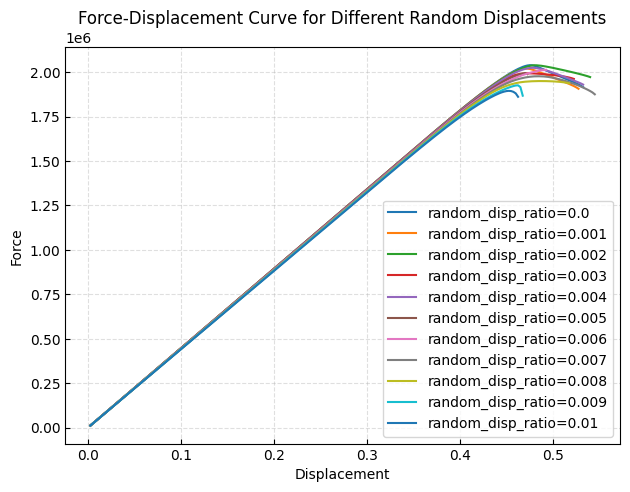

In [5]:
'''
绘制不同扰动下位移-反力曲线
'''
#绘制在一张图上
for i in range(11):
    random_disp_ratio = i * 1 / 1000
    df = pd.read_csv(f"../.output/with_buckling/{random_disp_ratio}/Node_disp.out", header = None, sep = " ")
    force = df.iloc[:, 0].values
    disp = df.iloc[:, 1].values
    plt.plot(disp, force, label=f"random_disp_ratio={random_disp_ratio}")
plt.xlabel("Displacement")
plt.ylabel("Force")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.title("Force-Displacement Curve for Different Random Displacements")
plt.legend()

plt.savefig(f"../.output/with_buckling/plot_node_disp.png")

## 绘制不考虑屈曲的位移-反力曲线

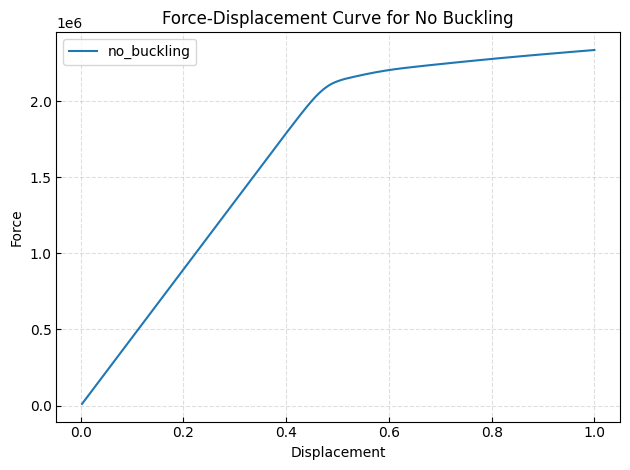

In [ ]:
'''
绘制no_buckling 的图
'''
df = pd.read_csv(f"../.output/no_buckling/Node_disp.out", header = None, sep = " ")
force = df.iloc[:, 0].values
disp = df.iloc[:, 1].values
plt.plot(disp, force, label=f"no_buckling")
plt.xlabel("Displacement")
plt.ylabel("Force")
plt.title("Force-Displacement Curve for No Buckling")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.legend()
plt.savefig(f"../.output/no_buckling/plot_node_disp.png")



## 绘制不同扰动下最大节间位移角-反力曲线

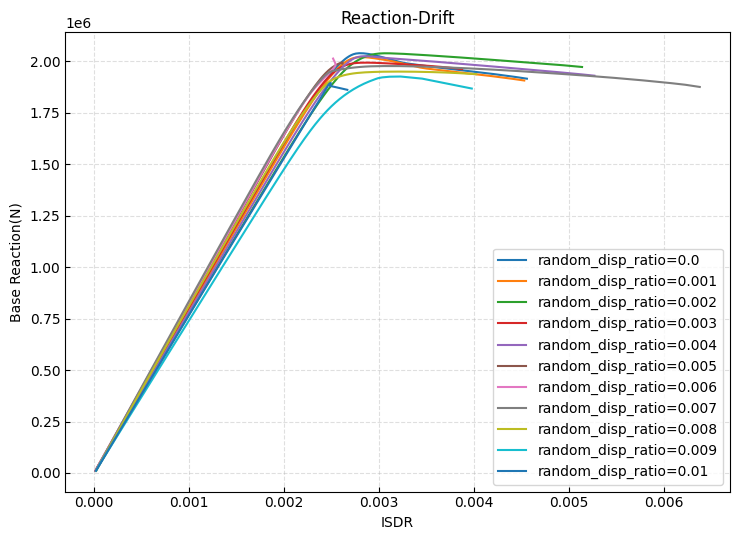

In [4]:
def find_slope_change_points(x_vals, y_vals, threshold=0.4):
    """Find points where adjacent segment slope changes more than threshold.

    threshold=0.4 means 40%.
    Returns indices i for point (x_vals[i], y_vals[i]), i in [1, n-2].
    """
    if len(x_vals) < 3:
        return []

    change_indices = []
    for i in range(1, len(x_vals) - 1):
        dx1 = x_vals[i] - x_vals[i - 1]
        dx2 = x_vals[i + 1] - x_vals[i]
        if abs(dx1) < 1e-15 or abs(dx2) < 1e-15:
            continue

        k1 = (y_vals[i] - y_vals[i - 1]) / dx1
        k2 = (y_vals[i + 1] - y_vals[i]) / dx2
        base = max(abs(k1), 1e-12)
        change_ratio = abs(k2 - k1) / base

        if change_ratio > threshold:
            change_indices.append(i)

    return change_indices


def read_reaction_and_max_drift(drift_file):
    reactions = []
    max_drifts = []

    with open(drift_file, "r", encoding="utf-8") as f:
        for line_idx, raw in enumerate(f, start=1):
            if line_idx == 1:
                continue  # Skip header
            line = raw.strip()
            if not line:
                continue

            parts = [p.strip() for p in line.split(",") if p.strip() != ""]
            if len(parts) < 2:
                raise ValueError(f"第 {line_idx} 行数据不足，至少需要反力和一个位移角。")

            reaction = float(parts[0])
            drifts = [float(v) for v in parts[1:]]

            # 取每一步层间位移角绝对值最大值用于包络关系图。
            max_drift = max(abs(v) for v in drifts)

            reactions.append(-reaction)
            max_drifts.append(max_drift)

    if not reactions:
        raise ValueError("未读取到有效数据，请检查 drift 文件内容。")

    return reactions, max_drifts


def plot_reaction_vs_max_drift(drift_file, random_disp_ratio):
    reactions, max_drifts = read_reaction_and_max_drift(drift_file)

    
    plt.plot(max_drifts, reactions, linewidth=1.5, markersize=4, label=f"random_disp_ratio={random_disp_ratio}")
    # # 标注斜率变化超过 40% 的点：画竖向虚线并标注对应横坐标。
    # change_indices = find_slope_change_points(max_drifts, reactions, threshold=0.4)
    # for idx in change_indices:
    #     x = max_drifts[idx]
    #     y = reactions[idx]
    #     plt.axvline(x=x, color="tab:red", linestyle="--", linewidth=1.0, alpha=0.8)
    #     plt.scatter([x], [y], color="tab:red", s=22, zorder=3)
    #     plt.annotate(
    #         f"x={x:.4e}",
    #         xy=(x, y),
    #         xytext=(6, 6),
    #         textcoords="offset points",
    #         fontsize=8,
    #         color="tab:red",
    #         bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="tab:red", alpha=0.7),
    #     )


ROOT_DIR = Path("../.output/with_buckling")
plt.figure(figsize=(7.5, 5.5))
for i in range(11):
    random_disp_ratio = i * 1 / 1000
    drift_file = ROOT_DIR / f"{random_disp_ratio}" / "drift.csv"
    plot_reaction_vs_max_drift(drift_file, random_disp_ratio)




plt.ylabel("Base Reaction(N)")
plt.xlabel("ISDR")
plt.title("Reaction-Drift")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(f"../.output/with_buckling/plot_reaction_drift.png")